# 2. Boiling point: Chemprop graph neural network

    **Demo purpose:** a compact “gold-standard” molecular-regression workflow. Chemprop converts each SMILES string to a molecular graph, passes messages along bonds, pools the learned atom-level representation, and predicts boiling point.

    This uses a random split for a fast workshop demonstration. A scaffold split is a better follow-up when the scientific claim is generalization to new chemical families.


In [1]:
from pathlib import Path
import shutil, subprocess, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

SEED = 42
SAMPLE_SIZE = 1500       # small enough for a workshop CPU run
EPOCHS = 20
ACQUIRED_DATA_FILE = Path('outputs/nist_acquisition/NIST_BP_SMILES.parquet')
PACKAGED_DATA_FILE = Path('data/CompoundData.parquet')
DATA_FILE = ACQUIRED_DATA_FILE if ACQUIRED_DATA_FILE.exists() else PACKAGED_DATA_FILE
OUTPUT = Path('outputs/bp_chemprop')
OUTPUT.mkdir(parents=True, exist_ok=True)

data = pd.read_parquet(DATA_FILE).dropna(subset=['SMILES', 'BP']).drop_duplicates('SMILES')
print(f'Using data source: {DATA_FILE}')
data = data[['SMILES', 'BP']].sample(n=min(SAMPLE_SIZE, len(data)), random_state=SEED).reset_index(drop=True)

indices = np.arange(len(data))
train, held_out = train_test_split(indices, test_size=0.20, random_state=SEED)
val, test = train_test_split(held_out, test_size=0.50, random_state=SEED)
data['split'] = 'train'
data.loc[val, 'split'] = 'val'
data.loc[test, 'split'] = 'test'

csv_file = OUTPUT / 'bp_data.csv'
data.to_csv(csv_file, index=False)
display(data.groupby('split')['BP'].agg(['size', 'mean', 'min', 'max']).round(2))


Using data source: data/CompoundData.parquet


,size,mean,min,max
split,,,,
test,150,463.90,239.50,665.67
train,1200,460.41,81.63,707.20
val,150,459.31,175.70,639.20


In [2]:
def chemprop_executable():
    executable = shutil.which('chemprop')
    if executable:
        return executable
    windows_candidate = Path(sys.executable).parent / 'Scripts' / 'chemprop.exe'
    if windows_candidate.exists():
        return str(windows_candidate)
    raise RuntimeError('Chemprop was not found. Create the workshop environment from environment.yml and select its kernel.')

model_dir = OUTPUT / 'model'
command = [
    chemprop_executable(), 'train', '-q', '-q',
    '--data-path', str(csv_file), '--smiles-columns', 'SMILES', '--target-columns', 'BP',
    '--task-type', 'regression', '--splits-column', 'split', '--output-dir', str(model_dir),
    '--epochs', str(EPOCHS), '--batch-size', '64', '--depth', '3', '--dropout', '0.05',
    '--pytorch-seed', str(SEED), '--num-workers', '0',
]
print(subprocess.list2cmdline(command))
subprocess.run(command, check=True)

prediction_file = OUTPUT / 'predictions.csv'
predict_command = [
    chemprop_executable(), 'predict', '--test-path', str(csv_file), '--smiles-columns', 'SMILES',
    '--model-paths', str(model_dir), '--preds-path', str(prediction_file),
    '--batch-size', '64', '--num-workers', '0',
]
subprocess.run(predict_command, check=True)


/home/runner/work/2026-avs-ml-vibe-coding-workshop/2026-avs-ml-vibe-coding-workshop/.venv/bin/chemprop train -q -q --data-path outputs/bp_chemprop/bp_data.csv --smiles-columns SMILES --target-columns BP --task-type regression --splits-column split --output-dir outputs/bp_chemprop/model --epochs 20 --batch-size 64 --depth 3 --dropout 0.05 --pytorch-seed 42 --num-workers 0


GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
Loading `train_dataloader` to estimate number of stepping batches.
/home/runner/work/2026-avs-ml-vibe-coding-workshop/2026-avs-ml-vibe-coding-workshop/.venv/lib/python3.11/site-packages/lightning/pytorch/loops/fit_loop.py:321: The number of training batches (19) is smaller than the logging interval Trainer(log_every_n_steps=50). Set a lower value for log_every_n_steps if you want to see logs for the training epoch.


Wrote config file to outputs/bp_chemprop/model/config.toml
┏━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name            ┃ Type               ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ message_passing │ BondMessagePassing │  227 K │ train │     0 │
│ 1 │ agg             │ NormAggregation    │      0 │ train │     0 │
│ 2 │ bn              │ Identity           │      0 │ train │     0 │
│ 3 │ predictor       │ RegressionFFN      │ 90.6 K │ train │     0 │
│ 4 │ X_d_transform   │ Identity           │      0 │ train │     0 │
│ 5 │ metrics         │ ModuleList         │      0 │ train │     0 │
└───┴─────────────────┴────────────────────┴────────┴───────┴───────┘
Trainable params: 318 K                                                         
Non-trainable params: 0                                                         
Total params: 318 K                                                            

Epoch 0/19                   0/19 0:00:00 • -:--:-- 0.00it/s v_num: 0.000       
Epoch 0/19 ╸                  1/19 0:00:00 • -:--:-- 0.00it/s v_num: 0.000      
                                                              train_loss_step:  
Epoch 0/19 ━╸                2/19 0:00:00 • 0:00:01 26.94it/s v_num: 0.000      
                                                              train_loss_step:  
Epoch 0/19 ━━╸               3/19 0:00:00 • 0:00:01 27.99it/s v_num: 0.000      
                                                              train_loss_step:  
Epoch 0/19 ━━━╸              4/19 0:00:00 • 0:00:01 28.36it/s v_num: 0.000      
                                                              train_loss_step:  
Epoch 0/19 ━━━━              5/19 0:00:00 • 0:00:01 28.43it/s v_num: 0.000      
                                                              train_loss_step:  
                                                              0.884             

Epoch 0/19 ━━━━━             6/19 0:00:00 • 0:00:01 28.76it/s v_num: 0.000      
                                                              train_loss_step:  
Epoch 0/19 ━━━━━━            7/19 0:00:00 • 0:00:01 28.87it/s v_num: 0.000      
                                                              train_loss_step:  
Epoch 0/19 ━━━━━━━           8/19 0:00:00 • 0:00:01 28.80it/s v_num: 0.000      
                                                              train_loss_step:  
Epoch 0/19 ━━━━━━━━          9/19 0:00:00 • 0:00:01 28.94it/s v_num: 0.000      
                                                              train_loss_step:  
Epoch 0/19 ━━━━━━━━╸         10/19 0:00:00 • 0:00:01 28.93it/s v_num: 0.000     
                                                               train_loss_step: 
Epoch 0/19 ━━━━━━━━━╸        11/19 0:00:00 • 0:00:01 29.18it/s v_num: 0.000     
                                                               train_loss_step: 
                            

Epoch 0/19 ━━━━━━━━━━╸       12/19 0:00:00 • 0:00:01 28.93it/s v_num: 0.000     
                                                               train_loss_step: 
Epoch 0/19 ━━━━━━━━━━━╸      13/19 0:00:00 • 0:00:01 28.96it/s v_num: 0.000     
                                                               train_loss_step: 
Epoch 0/19 ━━━━━━━━━━━━╸     14/19 0:00:00 • 0:00:01 28.65it/s v_num: 0.000     
                                                               train_loss_step: 
Epoch 0/19 ━━━━━━━━━━━━━     15/19 0:00:00 • 0:00:01 28.64it/s v_num: 0.000     
                                                               train_loss_step: 
Epoch 0/19 ━━━━━━━━━━━━━━    16/19 0:00:00 • 0:00:01 28.59it/s v_num: 0.000     
                                                               train_loss_step: 
Epoch 0/19 ━━━━━━━━━━━━━━━   17/19 0:00:00 • 0:00:01 28.50it/s v_num: 0.000     
                                                               train_loss_step: 
                            

... (69 outputs left out)

Predicting ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━    22/24 0:00:00 • 0:00:01 56.74it/s 

Predicting ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24/24 0:00:00 • 0:00:00 57.78it/s 


2026-10-11T01:49:15 - INFO:chemprop.cli.predict - Predictions saved to 'outputs/bp_chemprop/predictions.csv'


CompletedProcess(args=['/home/runner/work/2026-avs-ml-vibe-coding-workshop/2026-avs-ml-vibe-coding-workshop/.venv/bin/chemprop', 'predict', '--test-path', 'outputs/bp_chemprop/bp_data.csv', '--smiles-columns', 'SMILES', '--model-paths', 'outputs/bp_chemprop/model', '--preds-path', 'outputs/bp_chemprop/predictions.csv', '--batch-size', '64', '--num-workers', '0'], returncode=0)

,n,MAE (K),RMSE (K),R²
split,,,,
train,1200,20.68,31.52,0.80
val,150,24.04,38.12,0.71
test,150,24.55,35.13,0.78


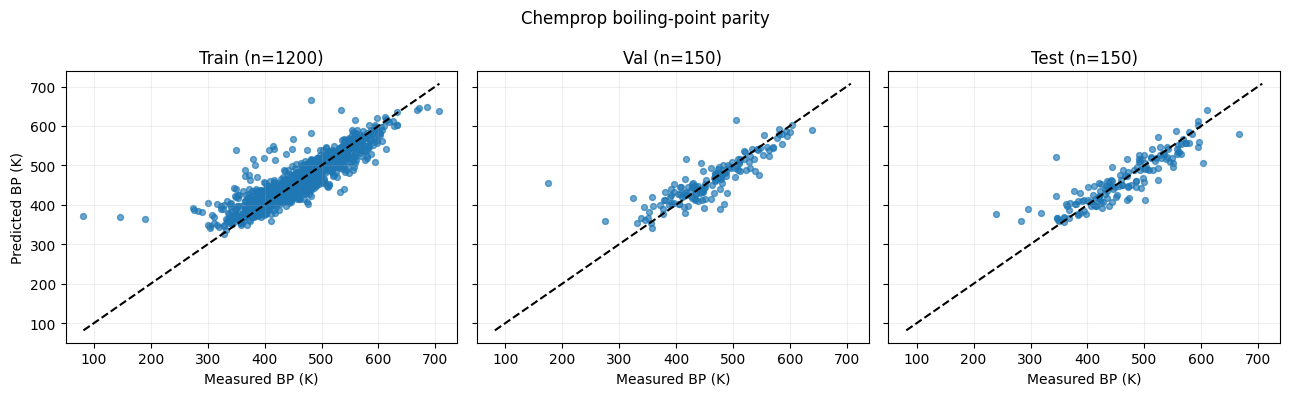

In [3]:
predictions = pd.read_csv(prediction_file)
candidate_columns = ['BP_pred', 'pred_0', 'BP']
prediction_column = next((column for column in candidate_columns if column in predictions.columns), None)
if prediction_column is None:
    numeric = predictions.select_dtypes(include='number').columns.tolist()
    if len(numeric) != 1:
        raise ValueError(f'Cannot identify prediction column: {predictions.columns.tolist()}')
    prediction_column = numeric[0]

results = data.copy()
results['predicted_BP'] = predictions[prediction_column].to_numpy()
rows = []
for split, subset in results.groupby('split', sort=False):
    rows.append({
        'split': split, 'n': len(subset),
        'MAE (K)': mean_absolute_error(subset.BP, subset.predicted_BP),
        'RMSE (K)': mean_squared_error(subset.BP, subset.predicted_BP) ** 0.5,
        'R²': r2_score(subset.BP, subset.predicted_BP),
    })
metrics = pd.DataFrame(rows).set_index('split')
display(metrics.round(2))

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharex=True, sharey=True)
limits = [min(results.BP.min(), results.predicted_BP.min()), max(results.BP.max(), results.predicted_BP.max())]
for ax, split in zip(axes, ['train', 'val', 'test']):
    subset = results.query('split == @split')
    ax.scatter(subset.BP, subset.predicted_BP, s=18, alpha=0.65)
    ax.plot(limits, limits, 'k--')
    ax.set(title=f'{split.title()} (n={len(subset)})', xlabel='Measured BP (K)')
    ax.grid(alpha=0.2)
axes[0].set_ylabel('Predicted BP (K)')
fig.suptitle('Chemprop boiling-point parity')
fig.tight_layout()
plt.show()


## Discussion

    The test panel is the relevant fast demonstration result; the validation partition selected the training epoch implicitly through Chemprop’s training process. The next notebook asks a complementary question: what can a pretrained molecular language model contribute before task-specific neural-network training?
